# ✅ Jawaban — Analisis & Visualisasi Data

Notebook ini berisi **jawaban** dari soal-soal di `07_latihan_analisis.ipynb`.

> ⚠️ **Coba kerjakan sendiri dulu** sebelum melihat jawaban di sini!

In [1]:
# ── Import pustaka ──
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

%matplotlib inline

print("✅ Pustaka siap digunakan")

✅ Pustaka siap digunakan


---
## Soal 1 — Baca Data

In [2]:
# ── Jawaban Soal 1 ──

# a) Baca CSV
df = pd.read_csv("data/pass_fail_data.csv")

print("=" * 50)
print("1a. 5 Baris Pertama")
print("=" * 50)
print(df.head())

print("\n" + "=" * 50)
print("1b. Info Dataset")
print("=" * 50)
print(df.info())

print("\n" + "=" * 50)
print("1c. Statistik Deskriptif")
print("=" * 50)
print(df.describe())

1a. 5 Baris Pertama
   student_id  attendance_pct  homework_pct  midterm_score  \
0           1              95            92             88   
1           2              88            85             79   
2           3              60            55             58   
3           4              72            70             65   
4           5              40            45             50   

   study_hours_per_week  pass  
0                    12     1  
1                    10     1  
2                     4     0  
3                     6     1  
4                     3     0  

1b. Info Dataset
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   student_id            100 non-null    int64
 1   attendance_pct        100 non-null    int64
 2   homework_pct          100 non-null    int64
 3   midterm_score         100 non-null    int64
 4   study_

---
## Soal 2 — Max Midterm Score

Gunakan `idxmax()` atau `nlargest()` untuk mencari nilai maksimum.

In [3]:
# ── Jawaban Soal 2 ──

# Cara 1: idxmax()
idx_max = df["midterm_score"].idxmax()
print("Cara 1 — idxmax():")
print(f"  student_id = {df.loc[idx_max, 'student_id']}")
print(f"  midterm_score = {df.loc[idx_max, 'midterm_score']}")
print()

# Cara 2: nlargest()
print("Cara 2 — nlargest():")
print(df.nlargest(1, "midterm_score")[["student_id", "midterm_score"]].to_string(index=False))

Cara 1 — idxmax():
  student_id = 75
  midterm_score = 97

Cara 2 — nlargest():
 student_id  midterm_score
         75             97


---
## Soal 3 — Top 5 Midterm Score

Gunakan `nlargest()` dengan parameter 5.

In [4]:
# ── Jawaban Soal 3 ──

top5 = df.nlargest(5, "midterm_score")[["student_id", "midterm_score", "pass"]]
print("Top 5 Mahasiswa dengan Midterm Score Tertinggi:")
print(top5.to_string(index=False))

Top 5 Mahasiswa dengan Midterm Score Tertinggi:
 student_id  midterm_score  pass
         75             97     1
         45             95     1
         96             94     1
         15             93     1
         66             93     1


---
## Soal 4 — Top 10 Kehadiran Terendah

Gunakan `nsmallest()` untuk nilai terendah.

In [5]:
# ── Jawaban Soal 4 ──

top10_low = df.nsmallest(10, "attendance_pct")[["student_id", "attendance_pct", "pass"]]
print("Top 10 Mahasiswa dengan Kehadiran Terendah:")
print(top10_low.to_string(index=False))

Top 10 Mahasiswa dengan Kehadiran Terendah:
 student_id  attendance_pct  pass
         11              30     0
         41              33     0
         71              34     0
         23              35     0
         53              36     0
         83              38     0
          5              40     0
         95              41     0
         35              42     0
         65              43     0


---
## Soal 5 — Visualisasi: Study Hours vs Pass

Bandingkan rata-rata jam belajar antara yang lulus dan tidak lulus menggunakan bar chart.

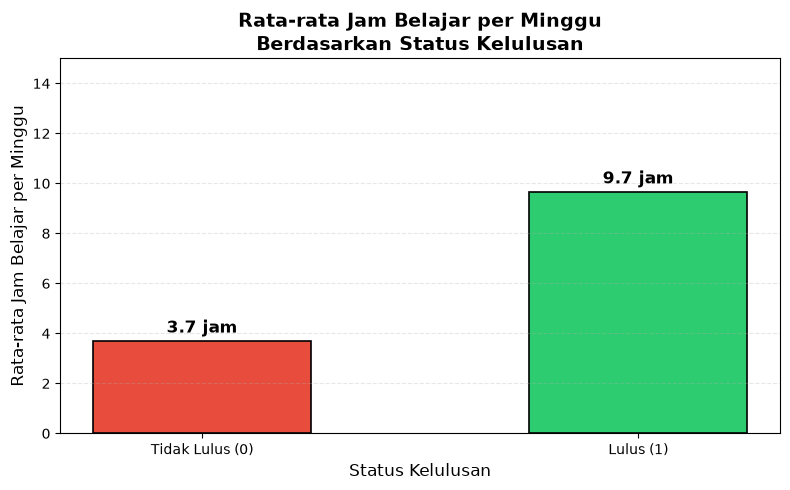


💡 Insight: Mahasiswa yang lulus rata-rata belajar lebih dari 2x lipat
    dibanding yang tidak lulus (9.7 vs 3.7 jam/minggu).


In [6]:
# ── Jawaban Soal 5 ──

# Hitung rata-rata study_hours per status pass
rata_jam = df.groupby("pass")["study_hours_per_week"].mean()

fig, ax = plt.subplots(figsize=(8, 5))

labels = ["Tidak Lulus (0)", "Lulus (1)"]
colors = ["#e74c3c", "#2ecc71"]

bars = ax.bar(labels, rata_jam.values, color=colors, edgecolor="black", linewidth=1.2, width=0.5)

# Tambahkan nilai di atas bar
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.1f} jam",
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=12, fontweight="bold")

ax.set_title("Rata-rata Jam Belajar per Minggu\nBerdasarkan Status Kelulusan",
             fontsize=14, fontweight="bold")
ax.set_ylabel("Rata-rata Jam Belajar per Minggu", fontsize=12)
ax.set_xlabel("Status Kelulusan", fontsize=12)
ax.set_ylim(0, 15)
ax.grid(axis="y", alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()

print("\n💡 Insight: Mahasiswa yang lulus rata-rata belajar lebih dari 2x lipat")
print(f"    dibanding yang tidak lulus ({rata_jam[1]:.1f} vs {rata_jam[0]:.1f} jam/minggu).")

---
## Soal 6 — Visualisasi: Attendance & Homework vs Pass

Scatter plot dengan sumbu X = attendance_pct, sumbu Y = homework_pct, warna berdasarkan pass.

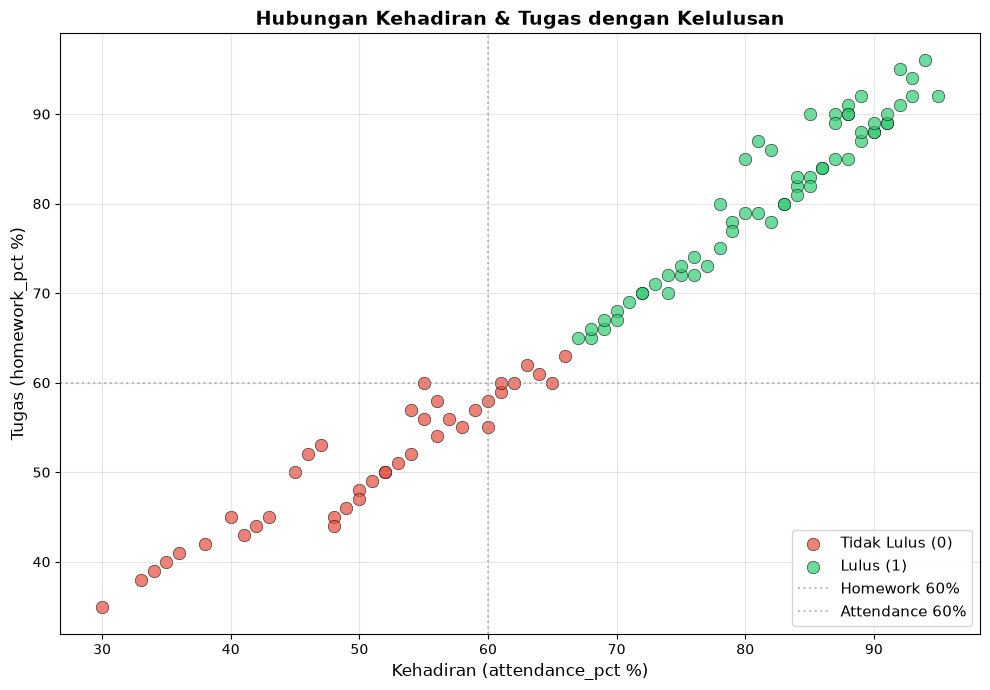

💡 Insight:
  - Mahasiswa dengan attendance > 60% DAN homework > 60% cenderung lulus
  - Mahasiswa dengan attendance < 60% DAN homework < 60% cenderung tidak lulus


In [7]:
# ── Jawaban Soal 6 ──

# Pisahkan data berdasarkan status
lulus = df[df["pass"] == 1]
tidak_lulus = df[df["pass"] == 0]

fig, ax = plt.subplots(figsize=(10, 7))

# Scatter plot
ax.scatter(tidak_lulus["attendance_pct"], tidak_lulus["homework_pct"],
           color="#e74c3c", label="Tidak Lulus (0)", alpha=0.7,
           s=80, edgecolor="black", linewidth=0.5)
ax.scatter(lulus["attendance_pct"], lulus["homework_pct"],
           color="#2ecc71", label="Lulus (1)", alpha=0.7,
           s=80, edgecolor="black", linewidth=0.5)

# Garis batas (threshold) — perkiraan visual
ax.axhline(y=60, color="gray", linestyle=":", alpha=0.5, label="Homework 60%")
ax.axvline(x=60, color="gray", linestyle=":", alpha=0.5, label="Attendance 60%")

ax.set_title("Hubungan Kehadiran & Tugas dengan Kelulusan",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Kehadiran (attendance_pct %)", fontsize=12)
ax.set_ylabel("Tugas (homework_pct %)", fontsize=12)
ax.legend(fontsize=11, loc="lower right")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 Insight:")
print("  - Mahasiswa dengan attendance > 60% DAN homework > 60% cenderung lulus")
print("  - Mahasiswa dengan attendance < 60% DAN homework < 60% cenderung tidak lulus")

---
## 📚 Ringkasan Jawaban

| Soal | Metode |
|------|--------|
| 1. Baca data | `pd.read_csv()`, `head()`, `info()`, `describe()` |
| 2. Max midterm_score | `idxmax()` atau `nlargest(1, ...)` |
| 3. Top 5 midterm_score | `nlargest(5, ...)` |
| 4. Top 10 attendance terendah | `nsmallest(10, ...)` |
| 5. Study Hours vs Pass | Bar chart: `groupby()`, `mean()`, `ax.bar()` |
| 6. Attendance & Homework vs Pass | Scatter plot: `ax.scatter()` dengan warna per kategori |